# Case Tracking

Chooses the cases to review from the latest verification run and tracks their state. Reads the runs that `2026-10-28 - Output Verification.ipynb` writes to `docs/validation/runs/`, and keeps the case log `docs/validation/cases.csv`.

Status in `cases.csv`, set by hand after the review:

- `open`: not reviewed yet
- `accepted`: real in the data, not an error; `note` gives the reason. An empty `patient_id` applies to the whole study (a pattern, backed by an SPL)
- `false_positive`: the check flags wrongly
- `fixed`: the error is fixed in the code; flagged again it is a regression, not flagged anymore the fix is verified

When a check changes its meaning, give it a new name in the verification notebook, so earlier reviews do not carry over.

In [1]:
import json
import os

import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

%config InlineBackend.figure_format = 'retina'

VALIDATION_DIR = os.path.join(os.getcwd(), '..', 'docs', 'validation')
RUNS_DIR = os.path.join(VALIDATION_DIR, 'runs')
CASES_PATH = os.path.join(VALIDATION_DIR, 'cases.csv')
CASE_KEYS = ['study_name', 'patient_id', 'check']
STATUSES = ['open', 'accepted', 'false_positive', 'fixed']
TOP_N = 1  # new cases per check (scope 'global') or per study and check (scope 'study')

## Load

In [2]:
# all verification runs, oldest first
runs = sorted(r for r in os.listdir(RUNS_DIR) if os.path.exists(os.path.join(RUNS_DIR, r, 'run.json')))
meta = {r: json.load(open(os.path.join(RUNS_DIR, r, 'run.json'))) for r in runs}
df_runs = pd.concat([pd.read_csv(os.path.join(RUNS_DIR, r, 'candidates.csv'), dtype={'study_name': str, 'patient_id': str}).assign(run=r)
                     for r in runs])
df_patients = pd.DataFrame([dict(run=r, study_name=s, n_patients=n) for r, m in meta.items() for s, n in m['n_patients'].items()])

# latest run: the candidates to choose from
LATEST = runs[-1]
df_cand = df_runs[df_runs.run == LATEST].drop(columns='run').reset_index(drop=True)
n_patients = df_patients[df_patients.run == LATEST].set_index('study_name').n_patients

df_cases = (pd.read_csv(CASES_PATH, dtype={'study_name': str, 'patient_id': str})
            if os.path.exists(CASES_PATH) else pd.DataFrame(columns=CASE_KEYS + ['value', 'status', 'spl', 'note']))

STUDIES = sorted(df_patients.study_name.unique())
PALETTE = dict(zip(STUDIES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#4a3aa7', '#17a2b8', '#8c564b']))
print(f"{len(runs)} runs, latest {LATEST} (notebook {meta[LATEST]['notebook_commit']}): {len(df_cand)} candidates; {len(df_cases)} cases")

1 runs, latest 2026-11-12_130036 (notebook e5ef000): 2179 candidates; 21 cases


## Patterns

Share of flagged patients per check and study in the latest run. High shares are patterns: review a few cases and close them study-wide.

In [3]:
df_cand.groupby(['check', 'study_name']).size().unstack().div(n_patients).round(3)

study_name,Flair,PEDAP,T1DEXI
check,,,
basal_above,NaN,NaN,0.050
bolus_basal_ratio,0.870,0.192,0.115
bolus_overlap,0.261,0.747,0.211
cgm_above,NaN,NaN,0.264
cgm_below,NaN,NaN,0.620
cgm_hour_jumps,0.974,0.970,0.545
cgm_irregular_hours,0.209,0.909,0.634
cgm_mean_vs_roc,0.009,0.020,0.014
coverage,0.035,0.162,0.044


## Choose Cases

Closed cases (`accepted`, `false_positive`) are removed before ranking, so the next candidates move up. `global` checks are ranked across studies, `study` checks per study. New cases are appended to `cases.csv` as `open`.

In [4]:
# remove closed cases, per patient and study-wide (empty patient_id)
closed = df_cases[df_cases.status.isin(['accepted', 'false_positive'])]
by_patient = df_cand.merge(closed[CASE_KEYS].drop_duplicates(), how='left', indicator=True)._merge.eq('both').values
by_study = df_cand.merge(closed[closed.patient_id.isna()][['study_name', 'check']].drop_duplicates(), how='left', indicator=True)._merge.eq('both').values
df_open = df_cand[~(by_patient | by_study)].sort_values('value', ascending=False)

# top N: across studies for global checks, per study for study checks
df_top = pd.concat([
    df_open[df_open.scope == 'global'].groupby('check').head(TOP_N),
    df_open[df_open.scope == 'study'].groupby(['study_name', 'check']).head(TOP_N),
]).merge(df_cases[CASE_KEYS + ['status']].drop_duplicates(CASE_KEYS), how='left')

# append new cases as open
new = df_top[df_top.status.isna()].assign(status='open')
df_cases = pd.concat([df_cases, new[CASE_KEYS + ['value', 'status']]], ignore_index=True)
df_cases.to_csv(CASES_PATH, index=False)
print(f"{len(new)} new cases")
df_top.sort_values(['scope', 'check', 'study_name'])

0 new cases


,study_name,patient_id,check,scope,value,status
8,T1DEXI,306,basal_above,global,0.593220,open
2,Flair,27,bolus_basal_ratio,global,4.983976,open
9,PEDAP,32,bolus_overlap,global,0.190805,open
10,T1DEXI,509,cgm_above,global,0.186380,open
11,T1DEXI,402,cgm_below,global,0.028459,open
1,PEDAP,84,cgm_hour_jumps,global,38.000000,open
0,T1DEXI,1120,cgm_irregular_hours,global,619.748056,open
7,T1DEXI,356,missing_basal,global,1.000000,open
6,T1DEXI,1563,missing_bolus,global,1.000000,open
3,Flair,89,missing_cgm,global,1.000000,open


## Review

Cases whose status no longer matches the latest run.

In [5]:
flagged = df_cand.set_index(CASE_KEYS).index

# fixed cases: flagged again = regression, not flagged anymore = fix verified
fixed = df_cases[df_cases.status == 'fixed']
display("Regressions (fixed, but flagged again):", fixed[fixed.set_index(CASE_KEYS).index.isin(flagged)])
display("Verified fixes (fixed and not flagged anymore):", fixed[~fixed.set_index(CASE_KEYS).index.isin(flagged)])

# accepted cases whose value changed by more than 50 % since the review: the reason may no longer hold
changed = df_cand.merge(df_cases[df_cases.status == 'accepted'], on=CASE_KEYS, suffixes=('', '_accepted'))
display("Accepted, but value changed:", changed[(changed.value / changed.value_accepted.astype(float) - 1).abs() > 0.5])

'Regressions (fixed, but flagged again):'

,study_name,patient_id,check,value,status,spl,note


'Verified fixes (fixed and not flagged anymore):'

,study_name,patient_id,check,value,status,spl,note


'Accepted, but value changed:'

,study_name,patient_id,check,scope,value,value_accepted,status,spl,note


## Status

In [6]:
# reviewed cases per study and check
pd.crosstab([df_cases.study_name, df_cases.check], df_cases.status).reindex(columns=STATUSES, fill_value=0)

status                          open  accepted  false_positive  fixed
study_name check                                                     
Flair      bolus_basal_ratio       1         0               0      0
           cgm_mean_vs_roc         1         0               0      0
           coverage                1         0               0      0
           missing_cgm             1         0               0      0
           tdd_mu_sigma            1         0               0      0
PEDAP      bolus_overlap           1         0               0      0
           cgm_hour_jumps          1         0               0      0
           cgm_mean_vs_roc         1         0               0      0
           coverage                1         0               0      0
           tdd_mu_sigma            1         0               0      0
T1DEXI     basal_above             1         0               0      0
           cgm_above               1         0               0      0
           cgm_below               1         0               0      0
           cgm_irregular_hours     1         0               0      0
           cgm_mean_vs_roc         1         0               0      0
           coverage                1         0               0      0
           missing_basal           1         0               0      0
           missing_bolus           1         0               0      0
           tdd_mu_sigma            1         0               0      0
           zero_basal              1         0               0      0
           zero_tdd                1         0               0      0

In [7]:
# cases still to review
df_cases[df_cases.status == 'open'].sort_values(['study_name', 'check'])

,study_name,patient_id,check,value,status,spl,note
2,Flair,27,bolus_basal_ratio,4.983976,open,NaN,NaN
17,Flair,29,cgm_mean_vs_roc,4.114585,open,NaN,NaN
20,Flair,33,coverage,0.680256,open,NaN,NaN
3,Flair,89,missing_cgm,1.000000,open,NaN,NaN
15,Flair,53,tdd_mu_sigma,9.302028,open,NaN,NaN
9,PEDAP,32,bolus_overlap,0.190805,open,NaN,NaN
1,PEDAP,84,cgm_hour_jumps,38.000000,open,NaN,NaN
13,PEDAP,29,cgm_mean_vs_roc,19.237047,open,NaN,NaN
18,PEDAP,75,coverage,1.104189,open,NaN,NaN
16,PEDAP,20,tdd_mu_sigma,6.948358,open,NaN,NaN


## Progress

Share of flagged patients per check over all runs, and how many flagged patients of the latest run are not yet closed.

In [8]:
# flagged share per run, study and check, computed from the run folders
df_rates = (df_runs.groupby(['run', 'study_name', 'check']).size().rename('n_flagged').reset_index()
            .merge(df_patients, on=['run', 'study_name'])
            .assign(rate=lambda d: d.n_flagged / d.n_patients))

# latest run: flagged patients that are still open after removing closed cases
df_open.groupby(['check', 'study_name']).size().unstack()

study_name,Flair,PEDAP,T1DEXI
check,,,
basal_above,NaN,NaN,25.0
bolus_basal_ratio,100.0,19.0,57.0
bolus_overlap,30.0,74.0,105.0
cgm_above,NaN,NaN,131.0
cgm_below,NaN,NaN,308.0
cgm_hour_jumps,112.0,96.0,271.0
cgm_irregular_hours,24.0,90.0,315.0
cgm_mean_vs_roc,1.0,2.0,7.0
coverage,4.0,16.0,22.0


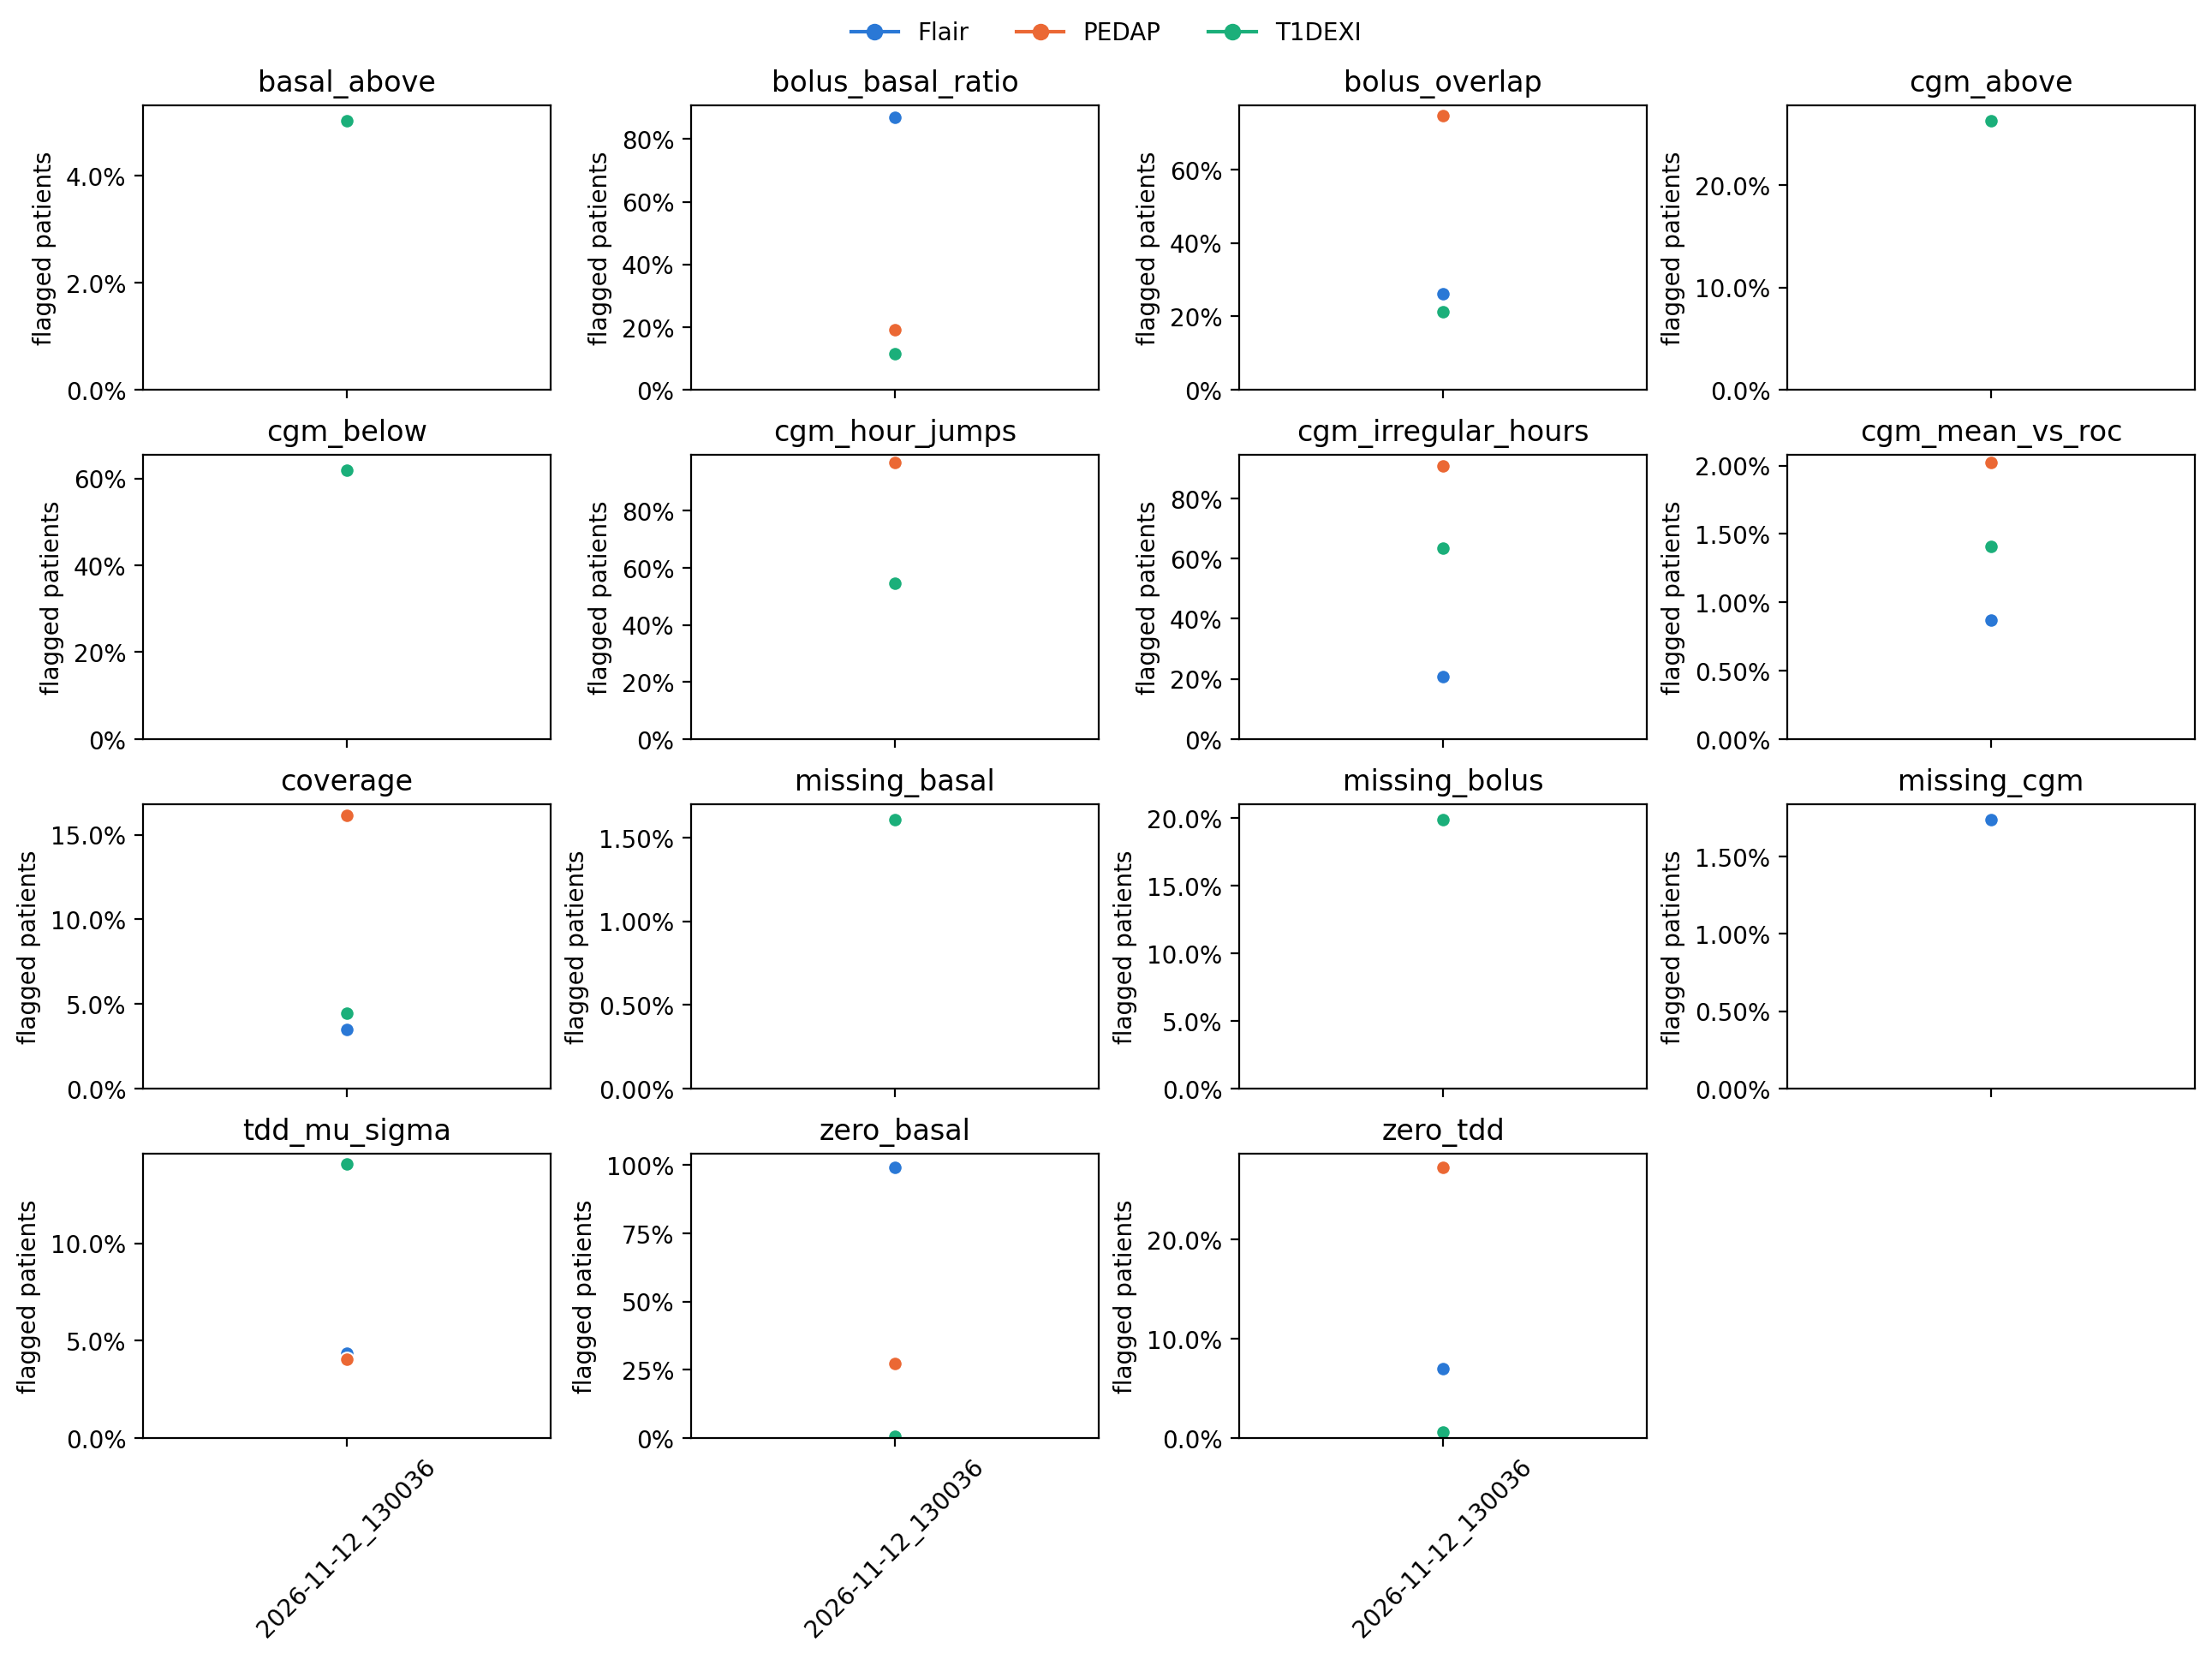

In [9]:
# progress over runs: flagged share per check, one line per study
checks = sorted(df_rates.check.unique())
n_cols = 4
n_rows = -(-len(checks) // n_cols)
f, AX = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.4 * n_rows), sharex=True, layout='constrained', squeeze=False)
for ax, check in zip(AX.flat, checks):
    sns.lineplot(df_rates[df_rates.check == check], x='run', y='rate', hue='study_name', hue_order=STUDIES, palette=PALETTE, marker='o', legend=False, ax=ax)
    ax.set(title=check, xlabel=None, ylabel='flagged patients', ylim=(0, None))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))  # rate is a share, show it as %
for ax in AX.flat[len(checks):]:
    ax.set_visible(False)
for ax in AX[-1]:
    ax.tick_params(axis='x', rotation=45)

# one legend for all subplots
handles = [Line2D([], [], color=PALETTE[s], marker='o', label=s) for s in STUDIES]
f.legend(handles=handles, loc='outside upper center', ncols=len(STUDIES), frameon=False)
f.savefig(os.path.join(VALIDATION_DIR, "progress.png"), dpi=300, bbox_inches="tight")

## Known Characteristics

Accepted cases with their reason: what researchers should know about the data. An empty `patient_id` applies to the whole study.

In [10]:
df_cases[df_cases.status == 'accepted'].sort_values(['study_name', 'check', 'patient_id'])[CASE_KEYS + ['spl', 'note']]

,study_name,patient_id,check,spl,note
